# Etapa 6 — Análisis de errores de la combinación actualizada

Se conserva el análisis por grosor, zona, grupo clínico y compresión, pero se
evalúan las **máscaras de validación cruzada de `05d`**, actualizadas después
de `05e` y `05f`. Ya no se usa verde con Otsu del 05 inicial.

La candidata combina 26 mapas del verde mediante regresión logística, trabaja
a mitad de resolución y se entrena equilibrando los vasos por grosor.
La regla de umbral principal es el valor fijo elegido en cada vuelta (cerrada
en la etapa 8, desvío 14.7). La fracción fija se muestra en el control como alternativa.

## Antes de ejecutar

1. Usar la copia completa del repositorio actualizado, incluidos `src`, `models`
   y los notebooks 05b–05f. Conservar los datos `data/raw`.
2. Ejecutar `05d_mascaras_desarrollo.ipynb` **con el código actualizado de 05f**
   para generar nuevamente `results/cache/mascaras_cv`. Si otra persona ya
   lo ejecutó, copiar esa carpeta completa. El ZIP de GitHub no la incluye.
   Si existían máscaras de una versión anterior, deben regenerarse: los
   archivos no contienen una etiqueta de versión que permita distinguirlas.
3. Ejecutar este cuaderno de arriba abajo. No se recalculan filtros ni modelos.

Las máscaras de cada imagen se obtuvieron sin entrenar con su persona.
No usar los pesos entrenados con las 30 imágenes para sustituir esas máscaras.
Las elecciones anteriores se hicieron con desarrollo; esta evaluación no
sustituye la prueba independiente.

Se eliminan las salidas y conclusiones antiguas. Las conclusiones nuevas se
calculan después de ejecutar. Los resultados se guardan en una carpeta nueva.


In [1]:
# En Colab, conectar Drive; fuera de Colab se omite.
try:
    from google.colab import drive
except ImportError:
    pass
else:
    drive.mount('/content/drive')


In [2]:
import os
import sys
from pathlib import Path

try:
    from google.colab import drive  # noqa: F401
    ROOT = Path('/content/drive/MyDrive/TP-PSI-G8-main')
except ImportError:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
assert (ROOT / 'src' / 'pipeline.py').exists(), 'Revisá ROOT.'
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print('Proyecto:', ROOT)


Proyecto: c:\Users\leahw\PSIB\TP-PSI-G8


In [3]:
import numpy as np
import pandas as pd

from src.config import RESULTS_DIR, WIDTH_LIMITS_PX
from src.data import dev_ids, load_image, load_vessels, load_fov
from src.fov import detect_fov_robust
from src import config as C
from src.pipeline import MASK_CACHE, load_dev_mask
from src.metrics import (
    matthews,
    dice,
    centerline_dice,
    centerline_sensitivity_by_class,
)

# Regla de umbral: valor fijo (etapa 8, desvío 14.7).
MASK_KIND = 'combinación valor fijo'
assert C.SEGMENT_FACTOR == 2
assert len(C.SEGMENT_FEATURES) == 26
assert C.SEGMENT_BALANCED_TRAINING is True, (
    'Esta versión requiere el código/configuración actualizados después de 05f. '
    'Si reemplazaste src con Colab abierto, reiniciá la sesión.'
)

OUT_DIR = RESULTS_DIR / '06_combinacion_equilibrada'
OUT_DIR.mkdir(parents=True, exist_ok=True)

ids = dev_ids()
faltantes = [i for i in ids if not (MASK_CACHE / f'{i}.npz').exists()]
assert not faltantes, (
    f'Faltan máscaras CV: {faltantes}. Ejecutá el 05d actualizado primero '
    'o copiá results/cache/mascaras_cv desde la corrida actualizada.'
)
tipos = ['combinación', 'referencia', 'combinación valor fijo', 'referencia valor fijo']
for i in ids:
    with np.load(MASK_CACHE / f'{i}.npz') as z:
        assert set(tipos).issubset(z.files), f'Máscaras incompletas: {i}'

# Registro de la configuración y de los archivos analizados.
import hashlib
import json
registro = {
    'mascara': MASK_KIND,
    'factor': C.SEGMENT_FACTOR,
    'mapas': C.SEGMENT_FEATURES,
    'entrenamiento_equilibrado': C.SEGMENT_BALANCED_TRAINING,
    'sha256_codigo': {
        n: hashlib.sha256((ROOT / 'src' / n).read_bytes()).hexdigest()
        for n in ['pipeline.py', 'config.py', 'metrics.py']
    },
    'sha256_mascaras': {
        i: hashlib.sha256((MASK_CACHE / f'{i}.npz').read_bytes()).hexdigest()
        for i in ids
    },
}
(OUT_DIR / 'configuracion_analizada.json').write_text(
    json.dumps(registro, indent=2, ensure_ascii=False), encoding='utf-8'
)

filas = []
ids = dev_ids()

for numero, imagen_id in enumerate(ids, start=1):
    referencia = load_vessels(imagen_id)
    campo_ref = load_fov(imagen_id)
    mascara = load_dev_mask(imagen_id, kind=MASK_KIND)
    assert mascara.shape == referencia.shape, f'Tamaño incorrecto: {imagen_id}'

    sensibilidad = centerline_sensitivity_by_class(
        mascara, referencia, WIDTH_LIMITS_PX, region=campo_ref
    )

    filas.append({
        "Imagen": imagen_id,
        "Matthews": matthews(mascara, referencia, campo_ref),
        "Dice": dice(mascara, referencia, campo_ref),
        "Dice línea central": centerline_dice(
            mascara, referencia, campo_ref
        ),
        "Sensibilidad finos": sensibilidad["fino"],
        "Sensibilidad medianos": sensibilidad["mediano"],
        "Sensibilidad gruesos": sensibilidad["grueso"],
    })

    # Checkpoint: una fila por imagen terminada, siempre de esta corrida.
    pd.DataFrame(filas).to_csv(OUT_DIR / '06_errores_por_grosor.csv', index=False)
    print(f"{numero}/{len(ids)} terminada: {imagen_id}", flush=True)

tabla_errores = pd.DataFrame(filas)
tabla_errores.to_csv(
    OUT_DIR / "06_errores_por_grosor.csv", index=False
)

columnas = [
    "Sensibilidad finos",
    "Sensibilidad medianos",
    "Sensibilidad gruesos",
]

display(
    tabla_errores[columnas]
    .mean()
    .rename("Sensibilidad media")
    .to_frame()
    .round(4)
)


1/30 terminada: 01_h
2/30 terminada: 02_h
3/30 terminada: 03_h
4/30 terminada: 04_h
5/30 terminada: 07_h
6/30 terminada: 08_h
7/30 terminada: 09_h
8/30 terminada: 10_h
9/30 terminada: 13_h
10/30 terminada: 14_h
11/30 terminada: 03_dr
12/30 terminada: 04_dr
13/30 terminada: 05_dr
14/30 terminada: 06_dr
15/30 terminada: 08_dr
16/30 terminada: 10_dr
17/30 terminada: 11_dr
18/30 terminada: 12_dr
19/30 terminada: 13_dr
20/30 terminada: 14_dr
21/30 terminada: 03_g
22/30 terminada: 04_g
23/30 terminada: 05_g
24/30 terminada: 06_g
25/30 terminada: 07_g
26/30 terminada: 08_g
27/30 terminada: 11_g
28/30 terminada: 12_g
29/30 terminada: 13_g
30/30 terminada: 14_g


,Sensibilidad media
Sensibilidad finos,0.3569
Sensibilidad medianos,0.8304
Sensibilidad gruesos,0.9264


### Interpretación por grosor

La tabla anterior corresponde a la combinación actualizada. La sensibilidad
es la proporción de la línea central del experto que cae dentro de la predicción.
Los valores antiguos (10,74 % en finos) describían verde con Otsu y no deben
usarse como resultado del método actual.

Como control externo, `05f` informa alrededor del 40 % de sensibilidad en finos
para la combinación equilibrada. La coincidencia se revisa con los valores de
esta corrida, sin copiarlos como resultados ya obtenidos.


## Control de las máscaras importadas

Se verifica Matthews contra las cuatro máscaras del `05d` recibido.
Esto ayuda a detectar cachés equivocadas. Las medias informadas son una
referencia de control, no resultados calculados en este archivo.
La verificación de finos también ayuda a distinguir las máscaras anteriores
al entrenamiento equilibrado, cuyo Matthews era parecido.


In [10]:
filas_control = []
for imagen_id in ids:
    referencia = load_vessels(imagen_id)
    campo_ref = load_fov(imagen_id)
    for tipo in tipos:
        m = load_dev_mask(imagen_id, kind=tipo)
        filas_control.append({
            'Imagen': imagen_id, 'Máscara': tipo,
            'Matthews': matthews(m, referencia, campo_ref),
        })
control = pd.DataFrame(filas_control)
control.to_csv(OUT_DIR / '06_control_mascaras_05d.csv', index=False)
medias_control = control.groupby('Máscara')['Matthews'].mean()
esperadas = pd.Series({
    'combinación': 0.7255, 'referencia': 0.7022,
    'combinación valor fijo': 0.7302, 'referencia valor fijo': 0.7040,
}, name='Media informada en el 05d recibido')
display(pd.concat([medias_control, esperadas], axis=1).round(4))
if (medias_control.sub(esperadas).abs() > 0.001).any():
    print('ATENCIÓN: las máscaras no reproducen el 05d recibido. '
          'Revisá su procedencia antes de interpretar el 06.')
# El 40 % de 05f es con fracción fija; con valor fijo los finos dan menos (35,7 %).
if MASK_KIND == 'combinación' and tabla_errores['Sensibilidad finos'].mean() < 0.37:
    print('ATENCIÓN: la sensibilidad en finos no coincide aproximadamente '
          'con el 40 % informado en 05f. Revisá que 05d se haya vuelto a '
          'ejecutar con entrenamiento equilibrado; no uses cachés antiguas.')


,Matthews,Media informada en el 05d recibido
combinación,0.7255,0.7255
combinación valor fijo,0.7302,0.7302
referencia,0.7022,0.7022
referencia valor fijo,0.7040,0.7040


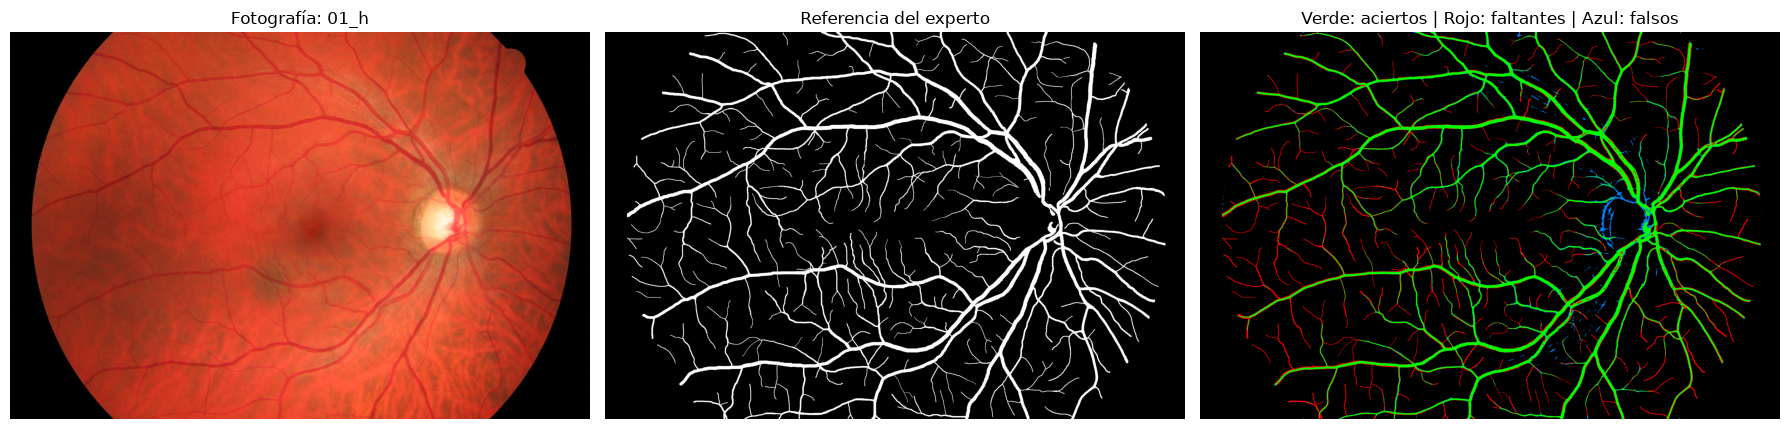

In [5]:
import matplotlib.pyplot as plt

imagen_id = "01_h"

foto = load_image(imagen_id)
referencia = load_vessels(imagen_id).astype(bool)
campo_ref = load_fov(imagen_id).astype(bool)
campo_auto = detect_fov_robust(foto)

mascara = load_dev_mask(imagen_id, kind=MASK_KIND)

aciertos = mascara & referencia & campo_ref
faltantes = ~mascara & referencia & campo_ref
falsos = mascara & ~referencia & campo_ref

errores = np.zeros((*referencia.shape, 3), dtype=np.uint8)
errores[aciertos] = [0, 255, 0]
errores[faltantes] = [255, 0, 0]
errores[falsos] = [0, 130, 255]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(foto)
axes[0].set_title(f"Fotografía: {imagen_id}")

axes[1].imshow(referencia, cmap="gray")
axes[1].set_title("Referencia del experto")

axes[2].imshow(errores)
axes[2].set_title("Verde: aciertos | Rojo: faltantes | Azul: falsos")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


### Inspección visual: 01_h

Verde indica vasos acertados, rojo vasos omitidos y azul falsas detecciones,
dentro del campo de referencia. Con el valor fijo, el algoritmo acierta casi
todos los vasos gruesos y medianos, incluidas las arcadas principales. Lo que
pierde son sobre todo las ramas finas de la periferia y entre los vasos grandes (la sensibilidad de 36 % en finos). Las falsas detecciones son pocas y se concentran en el borde del disco óptico, donde el cambio brusco de brillo se parece a un vaso para los filtros.


In [6]:
from src.data import load_split

# Recuperamos las métricas guardadas por si se reinició la sesión.
tabla_errores = pd.read_csv(
    OUT_DIR / "06_errores_por_grosor.csv"
)

metadatos = load_split()[
    ["image", "group", "person", "more_compressed"]
]

analisis = tabla_errores.merge(
    metadatos,
    left_on="Imagen",
    right_on="image",
    validate="one_to_one",
)

analisis["Grupo"] = analisis["group"].map({
    "h": "Sanos",
    "dr": "Retinopatía diabética",
    "g": "Glaucoma",
})

# Funciona tanto si la columna se leyó como booleano o como texto.
analisis["Compresión"] = (
    analisis["more_compressed"]
    .astype(str).str.lower()
    .map({"true": "Mayor", "false": "Menor"})
)

assert analisis[["Grupo", "Compresión"]].notna().all().all()

def resumir_grupos(columnas):
    return analisis.groupby(columnas).agg(
        Imagenes=("Imagen", "count"),
        Matthews=("Matthews", "mean"),
        Dice_linea_central=("Dice línea central", "mean"),
        Sensibilidad_finos=("Sensibilidad finos", "mean"),
    ).round(4)

print("Por grupo clínico:")
display(resumir_grupos(["Grupo"]))

print("Por compresión:")
display(resumir_grupos(["Compresión"]))

print("Grupo clínico dentro de cada nivel de compresión:")
display(resumir_grupos(["Compresión", "Grupo"]))

analisis.to_csv(
    OUT_DIR / "06_errores_con_metadatos.csv",
    index=False,
)


Por grupo clínico:


,Imagenes,Matthews,Dice_linea_central,Sensibilidad_finos
Grupo,,,,
Glaucoma,10,0.7411,0.7340,0.3553
Retinopatía diabética,10,0.6794,0.6765,0.3857
Sanos,10,0.7701,0.8044,0.3297


Por compresión:


,Imagenes,Matthews,Dice_linea_central,Sensibilidad_finos
Compresión,,,,
Mayor,12,0.7448,0.7603,0.3647
Menor,18,0.7204,0.7236,0.3517


Grupo clínico dentro de cada nivel de compresión:


Imagenes  Matthews  Dice_linea_central  \
Compresión Grupo                                                           
Mayor      Glaucoma                      4    0.7321              0.7387   
           Retinopatía diabética         2    0.6711              0.6595   
           Sanos                         6    0.7779              0.8083   
Menor      Glaucoma                      6    0.7471              0.7309   
           Retinopatía diabética         8    0.6815              0.6807   
           Sanos                         4    0.7584              0.7985   

                                  Sensibilidad_finos  
Compresión Grupo                                      
Mayor      Glaucoma                           0.3426  
           Retinopatía diabética              0.3646  
           Sanos                              0.3795  
Menor      Glaucoma                           0.3638  
           Retinopatía diabética              0.3910  
           Sanos                              0.2550

### Interpretación por grupo y compresión

- **Grupo:** retinopatía tiene el menor Matthews (0,679) y el menor Dice de línea
  central (0,677); sanos el mayor (0,770 y 0,804); glaucoma queda en el medio
  (0,741 y 0,734). Es el mismo orden que con la fracción fija.
- **Vasos finos:** el orden se invierte: retinopatía 38,6 %, glaucoma 35,5 % y
  sanos 33,0 %. Es compatible con lo visto en `01c` (los expertos marcaron más
  anchos los vasos de sanos), pero este cuaderno no lo prueba.
- **Compresión:** las más comprimidas dan algo más (Matthews 0,745 contra 0,720),
  pero compresión y grupo están mezclados: la mitad de las más comprimidas son de
  sanos y casi todas las de retinopatía son menos comprimidas. Dentro de cada
  nivel de compresión, retinopatía sigue siendo el peor grupo, así que la
  diferencia se asocia al grupo y no a la compresión. Algunas celdas son muy
  chicas (retinopatía más comprimida: 2 imágenes).


## Errores por zona

Se aproxima el centro del disco óptico mediante el máximo de
brillo de la fotografía suavizada dentro del campo automático.

Se define una zona circular con radio de 0,10 veces el diámetro
del campo. Este radio es una decisión exploratoria, no una
medida anatómica validada.

Se compara Matthews cerca de ese centro y en el resto del campo,
sin modificar la segmentación.

1/30 terminada: 01_h
2/30 terminada: 02_h
3/30 terminada: 03_h
4/30 terminada: 04_h
5/30 terminada: 07_h
6/30 terminada: 08_h
7/30 terminada: 09_h
8/30 terminada: 10_h
9/30 terminada: 13_h
10/30 terminada: 14_h
11/30 terminada: 03_dr
12/30 terminada: 04_dr
13/30 terminada: 05_dr
14/30 terminada: 06_dr
15/30 terminada: 08_dr
16/30 terminada: 10_dr
17/30 terminada: 11_dr
18/30 terminada: 12_dr
19/30 terminada: 13_dr
20/30 terminada: 14_dr
21/30 terminada: 03_g
22/30 terminada: 04_g
23/30 terminada: 05_g
24/30 terminada: 06_g
25/30 terminada: 07_g
26/30 terminada: 08_g
27/30 terminada: 11_g
28/30 terminada: 12_g
29/30 terminada: 13_g
30/30 terminada: 14_g


,Matthews,Dice
Zona,,
Cerca del disco estimado,0.7095,0.7623
Resto del campo,0.7310,0.7504


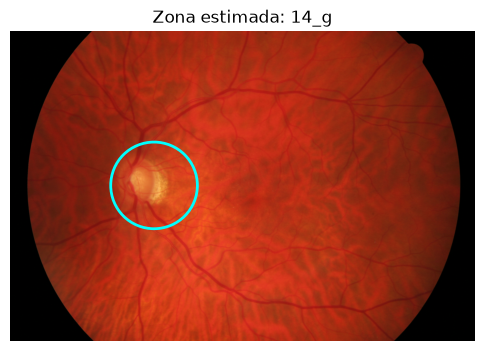

In [7]:
from scipy.ndimage import gaussian_filter
from src.fov import fov_diameter

filas_zonas = []

for numero, imagen_id in enumerate(ids, start=1):
    foto = load_image(imagen_id)
    referencia = load_vessels(imagen_id)
    campo_ref = load_fov(imagen_id).astype(bool)
    campo_auto = detect_fov_robust(foto)
    diametro = fov_diameter(campo_auto)

    mascara = load_dev_mask(imagen_id, kind=MASK_KIND)

    # Localización aproximada del disco, usando solo la fotografía.
    brillo = foto.astype(np.float32).mean(axis=2)
    suave = gaussian_filter(brillo, sigma=0.02 * diametro)
    suave[~campo_auto] = -np.inf

    cy, cx = np.unravel_index(np.argmax(suave), suave.shape)

    yy, xx = np.ogrid[:referencia.shape[0], :referencia.shape[1]]
    cerca = (yy - cy)**2 + (xx - cx)**2 <= (0.10 * diametro)**2

    for nombre, region in {
        "Cerca del disco estimado": campo_ref & cerca,
        "Resto del campo": campo_ref & ~cerca,
    }.items():
        filas_zonas.append({
            "Imagen": imagen_id,
            "Zona": nombre,
            "Centro x": cx,
            "Centro y": cy,
            "Matthews": matthews(mascara, referencia, region),
            "Dice": dice(mascara, referencia, region),
        })

    print(f"{numero}/{len(ids)} terminada: {imagen_id}", flush=True)

tabla_zonas = pd.DataFrame(filas_zonas)
tabla_zonas.to_csv(
    OUT_DIR / "06_errores_por_zona.csv", index=False
)

display(
    tabla_zonas.groupby("Zona")[["Matthews", "Dice"]]
    .mean()
    .round(4)
)

# Control visual de la ubicación estimada en la última imagen.
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(foto)
ax.add_patch(
    plt.Circle(
        (cx, cy), 0.10 * diametro,
        fill=False, color="cyan", linewidth=2
    )
)
ax.set_title(f"Zona estimada: {imagen_id}")
ax.axis("off")
plt.show()


### Interpretación por zona

Cerca del disco estimado, Matthews es algo menor (0,710 contra 0,731), pero el Dice es algo mayor (0,762 contra 0,750): no hay una diferencia clara entre zonas. El radio de 0,10 del diámetro se mantuvo como estaba, sin retocarlo. En la imagen de control (14_g) el círculo cae sobre el disco; el máximo de brillo es una localización aproximada y esa imagen no valida las otras 29.


In [8]:
from src.config import SEED

analisis = pd.read_csv(
    OUT_DIR / "06_errores_con_metadatos.csv"
)

metricas = ["Matthews", "Dice línea central"]
valores = analisis[metricas].to_numpy(dtype=float)

assert np.isfinite(valores).all(), "Hay métricas faltantes."

personas = analisis["person"].unique()
indice_persona = pd.Categorical(
    analisis["person"], categories=personas
).codes

# Cada fila contiene cuántas veces se sorteó cada persona.
rng = np.random.default_rng(SEED)
remuestreos = np.array([
    np.bincount(
        rng.integers(0, len(personas), size=len(personas)),
        minlength=len(personas),
    )
    for _ in range(2000)
])

comparaciones = [
    ("Grupo", "Sanos"),
    ("Grupo", "Retinopatía diabética"),
    ("Grupo", "Glaucoma"),
    ("Compresión", "Mayor"),
]

filas_intervalos = []

for columna, grupo in comparaciones:
    pertenece = analisis[columna].eq(grupo).to_numpy()
    resto = ~pertenece

    diferencia = (
        valores[pertenece].mean(axis=0)
        - valores[resto].mean(axis=0)
    )

    diferencias_boot = []

    for conteos in remuestreos:
        pesos = conteos[indice_persona]

        if pesos[pertenece].sum() == 0 or pesos[resto].sum() == 0:
            continue

        media_grupo = np.average(
            valores[pertenece], axis=0,
            weights=pesos[pertenece],
        )
        media_resto = np.average(
            valores[resto], axis=0,
            weights=pesos[resto],
        )
        diferencias_boot.append(media_grupo - media_resto)

    inferior, superior = np.percentile(
        diferencias_boot, [2.5, 97.5], axis=0
    )

    for j, metrica in enumerate(metricas):
        filas_intervalos.append({
            "Comparación": f"{grupo} frente al resto",
            "Métrica": metrica,
            "Diferencia": diferencia[j],
            "Límite inferior 95%": inferior[j],
            "Límite superior 95%": superior[j],
            "Peor con intervalo bajo cero": superior[j] < 0,
        })

tabla_intervalos = pd.DataFrame(filas_intervalos)

tabla_intervalos.to_csv(
    OUT_DIR / "06_intervalos_subgrupos.csv", index=False
)

display(tabla_intervalos.round(4))


,Comparación,Métrica,Diferencia,Límite inferior 95%,Límite superior 95%,Peor con intervalo bajo cero
0,Sanos frente al resto,Matthews,0.0598,0.0336,0.0900,False
1,Sanos frente al resto,Dice línea central,0.0991,0.0729,0.1318,False
2,Retinopatía diabética frente al resto,Matthews,-0.0762,-0.1077,-0.0479,True
3,Retinopatía diabética frente al resto,Dice línea central,-0.0927,-0.1371,-0.0509,True
4,Glaucoma frente al resto,Matthews,0.0164,-0.0171,0.0538,False
5,Glaucoma frente al resto,Dice línea central,-0.0064,-0.0437,0.0416,False
6,Mayor frente al resto,Matthews,0.0244,-0.0198,0.0685,False
7,Mayor frente al resto,Dice línea central,0.0366,-0.0226,0.0946,False


## Cierre de esta versión

La siguiente celda redacta un resumen numérico usando exclusivamente esta
corrida. Si un subgrupo es peor en las dos métricas, lo señala: la regla de
corrección dirigida de la etapa 6 se resuelve en la decisión de abajo (en estacorrida se dispara para retinopatía y no se aplica; desvío 14.10 del plan). Las mejoras de `05f` ya forman parte del algoritmo analizado.


In [9]:
from IPython.display import Markdown, display

medias = tabla_errores.select_dtypes(include='number').mean()
grupos = analisis.groupby('Grupo')['Matthews'].mean()
disparadores = tabla_intervalos.groupby('Comparación')[
    'Peor con intervalo bajo cero'
].all()
activos = list(disparadores.index[disparadores])
decision = (
    'Hay deterioro con intervalo bajo cero en ambas métricas para: '
    + ', '.join(activos)
    + '. Revisar la regla de corrección dirigida y lo ya abordado en 05f; '
      'este cuaderno no realiza una corrección adicional.'
    if activos else
    'Ningún subgrupo tiene un intervalo completamente bajo cero en ambas '
    'métricas. No se activa una nueva corrección dirigida por este criterio.'
)
texto = f"""## Resumen calculado de la corrida

- **Máscara:** {MASK_KIND}, guardada con validación por personas en 05d.
- **Matthews medio:** {medias['Matthews']:.4f}.
- **Dice medio:** {medias['Dice']:.4f}.
- **Dice de línea central medio:** {medias['Dice línea central']:.4f}.
- **Sensibilidad de línea central:** finos {medias['Sensibilidad finos']:.1%},
  medianos {medias['Sensibilidad medianos']:.1%},
  gruesos {medias['Sensibilidad gruesos']:.1%}.
- **Menor Matthews por grupo:** {grupos.idxmin()} ({grupos.min():.4f}).

{decision}

Los intervalos son exploratorios, sin ajuste por comparaciones múltiples.
Grupo y compresión están mezclados; las diferencias no demuestran causas.
El disco se localizó de forma aproximada. Las decisiones anteriores usaron
desarrollo: estos resultados no sustituyen la prueba independiente.
"""
display(Markdown(texto))
(OUT_DIR / '06_resumen.md').write_text(texto, encoding='utf-8')


## Resumen calculado de la corrida

- **Máscara:** combinación valor fijo, guardada con validación por personas en 05d.
- **Matthews medio:** 0.7302.
- **Dice medio:** 0.7517.
- **Dice de línea central medio:** 0.7383.
- **Sensibilidad de línea central:** finos 35.7%,
  medianos 83.0%,
  gruesos 92.6%.
- **Menor Matthews por grupo:** Retinopatía diabética (0.6794).

Hay deterioro con intervalo bajo cero en ambas métricas para: Retinopatía diabética frente al resto. Revisar la regla de corrección dirigida y lo ya abordado en 05f; este cuaderno no realiza una corrección adicional.

Los intervalos son exploratorios, sin ajuste por comparaciones múltiples.
Grupo y compresión están mezclados; las diferencias no demuestran causas.
El disco se localizó de forma aproximada. Las decisiones anteriores usaron
desarrollo: estos resultados no sustituyen la prueba independiente.


878

## Decisión (escrita después de correr, 4/11)

**Máscara:** combinación con valor fijo (regla final, etapa 8, desvío 14.7), regenerada con `05d`; reproduce exacto el control (Matthews 0,7302).

- **Por grosor** (sensibilidad de línea central): finos 35,7 %, medianos 83,0 %, gruesos 92,6 %. Los vasos finos siguen siendo **la limitación principal**. Con el valor fijo se pierden unos 5 puntos de finos frente a la fracción fija (40,4 %), a cambio de mejor Matthews y mejor concordancia clínica. Por eso el aviso del control (pensado para el 40 % de la fracción fija) no aplica.
- **Por grupo:** retinopatía es peor que el resto en Matthews (−0,076; −0,108 a −0,048) **y** en Dice de línea central (−0,093; −0,137 a −0,051). **Se dispara la regla de corrección dirigida** (etapa 6; desvío 14.3).
- **Por compresión:** sin diferencia demostrada (Matthews +0,024; −0,020 a +0,069); la diferencia aparente viene de la mezcla con el grupo.
- **Por zona:** cerca del disco óptico estimado, Matthews 0,710 contra 0,731 en el resto, pero Dice 0,762 contra 0,750: las dos medidas van en sentidos opuestos y no hay una diferencia clara (descriptivo, sin intervalo). Las pocas falsas detecciones del borde del disco no pesan en el total.

**Corrección dirigida: no se aplica (desvío 14.10 del plan).** El desvío 14.8 cerró el algoritmo sin excepciones, y la corrección prevista para retinopatía (limpieza por forma, que quita componentes no alargadas como las lesiones) ya se probó en `05c` y no cumplió la condición de no bajar los vasos finos; en `05c` se probó sobre el detector de líneas, no sobre la combinación final. Se informa como limitación: el algoritmo segmenta peor en retinopatía diabética.